In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from parameters import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

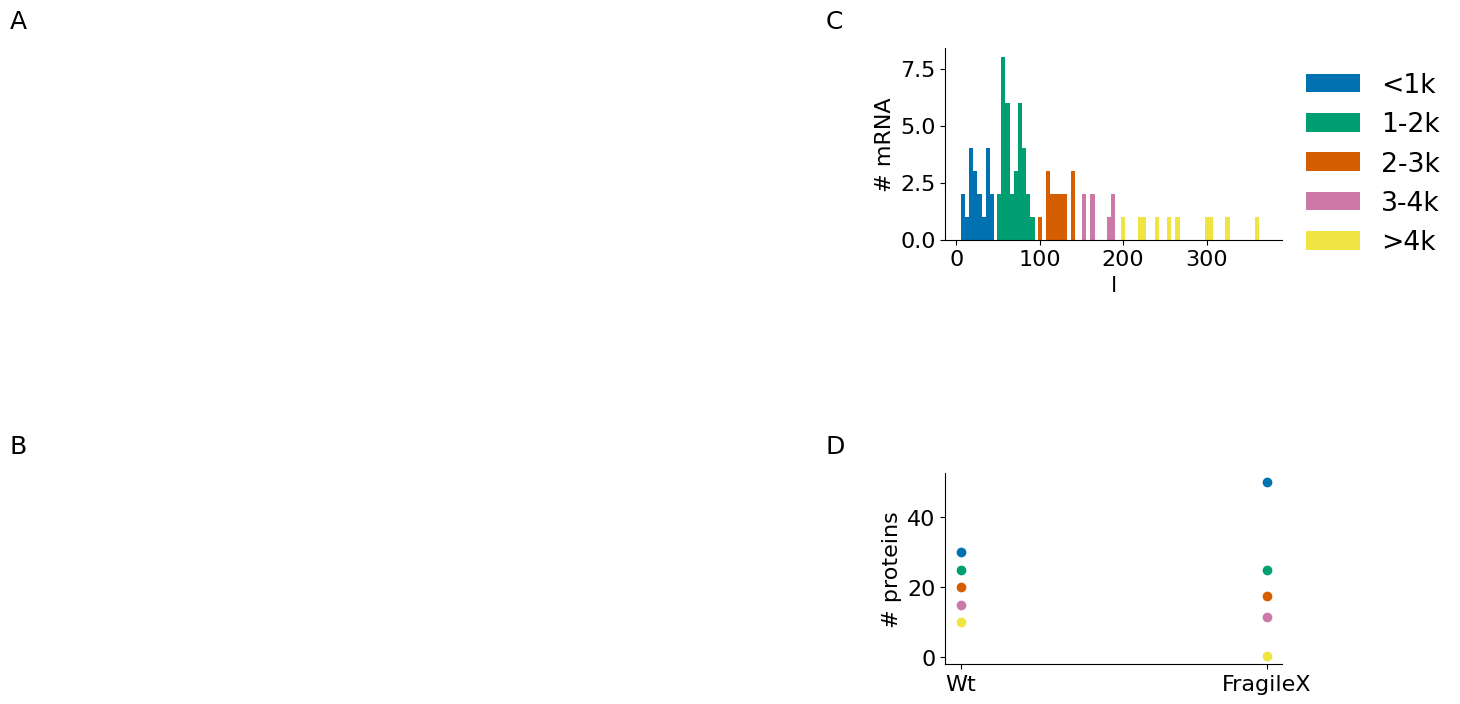

In [2]:
layout = '''
    AACC
    AACC
    BBDD
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [2,0.1,1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABCD':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABCD', postfix='', offset_left=1.2)
for a in list('ABCD'):
    axes[a].set_axis_off()

    
ax = fig.add_subplot(gs[0,2])
bin_width = 5
binwin = np.arange(l_samples[0],l_samples[s_1k[-1]],bin_width)
ax.hist(l_samples[s_1k], label = ['<1k'], color = palette[0], bins = binwin)
binwin = np.arange(l_samples[s_1k[-1]],l_samples[s_2k[-1]],bin_width)
ax.hist(l_samples[s_2k], color = palette[1], label = '1-2k', bins = binwin)
binwin = np.arange(l_samples[s_2k[-1]],l_samples[s_3k[-1]],bin_width)
ax.hist(l_samples[s_3k], color = palette[2], label = '2-3k', bins = binwin)
binwin = np.arange(l_samples[s_3k[-1]],l_samples[s_4k[-1]],bin_width)
ax.hist(l_samples[s_4k], color = palette[3], label = '3-4k', bins = binwin)
binwin = np.arange(l_samples[s_4k[-1]],l_samples[b_4k[-1]],bin_width)
ax.hist(l_samples[b_4k], color = palette[4], label = '>4k', bins = binwin)
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
ax.set_xlabel('l')
ax.set_ylabel('# mRNA')
clear_axes(ax)

#can be replaced by actual measurements
mock_data = np.zeros([2,5])
mock_data[0] = np.array([0.3,0.25,0.2,0.15,0.1])*100
mock_data[1] = np.array([0.5,0.25,0.175, 0.115,0.005])*100

Rs = ['Wt', 'FragileX']
ax = fig.add_subplot(gs[2,2])
ax.scatter(Rs, mock_data[:,0], label = '<1k')
ax.scatter(Rs, mock_data[:,1], label = '1-2k')
ax.scatter(Rs, mock_data[:,2], label = '2-3k')
ax.scatter(Rs, mock_data[:,3], label = '3-4k')
ax.scatter(Rs, mock_data[:,4], label = '>4k')
ax.set_ylabel('# proteins')
clear_axes(ax)

plt.savefig(figures_path+'fig1_problem_description.pdf')
plt.show()